<a href="https://colab.research.google.com/github/DVKOMORI/Calculo_Numerico/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

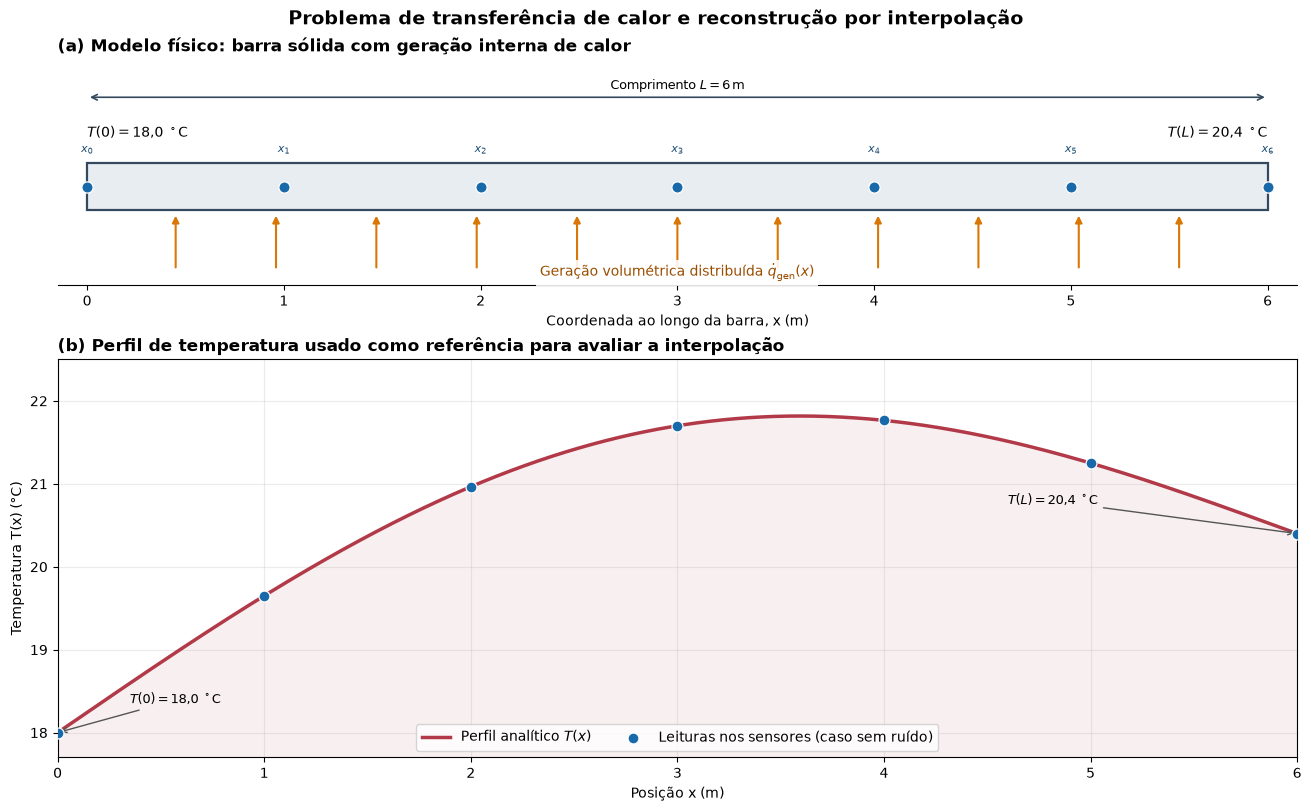

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


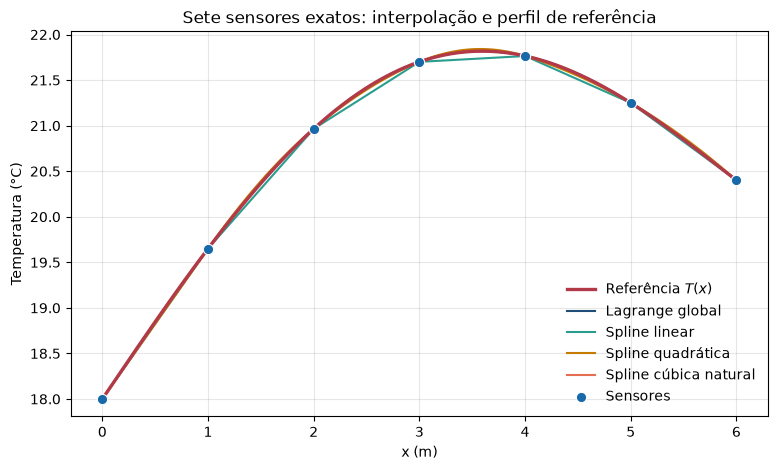

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
def mostrar_tabela(tabela, colunas_cientificas=(), colunas_decimais=()):
    """Mostra a tabela com os erros em notação científica."""
    visivel = tabela.copy()
    for coluna in colunas_cientificas:
        visivel[coluna] = visivel[coluna].map(lambda valor: f"{valor:.3e}")
    for coluna in colunas_decimais:
        visivel[coluna] = visivel[coluna].map(lambda valor: f"{valor:.3f}")
    display(visivel)

mostrar_tabela(
    metricas_7,
    colunas_cientificas=("Erro máximo (°C)", "MAE (°C)", "RMSE (°C)"),
)

cores = {
    "Lagrange global": "#1f4e79",
    "Spline linear": "#2a9d8f",
    "Spline quadrática": "#c47b00",
    "Spline cúbica natural": "#e76f51",
}

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_fino, T_fino, color="#b23a48", lw=2.4, label=r"Referência $T(x)$", zorder=3)
for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), lw=1.5, color=cores[nome], label=nome)
ax.scatter(x_nos_7, y_nos_7, s=55, facecolor="#1769aa", edgecolor="white",
           linewidth=0.8, zorder=5, label="Sensores")
ax.set_xlabel("x (m)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Sete sensores exatos: interpolação e perfil de referência")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
plt.show()

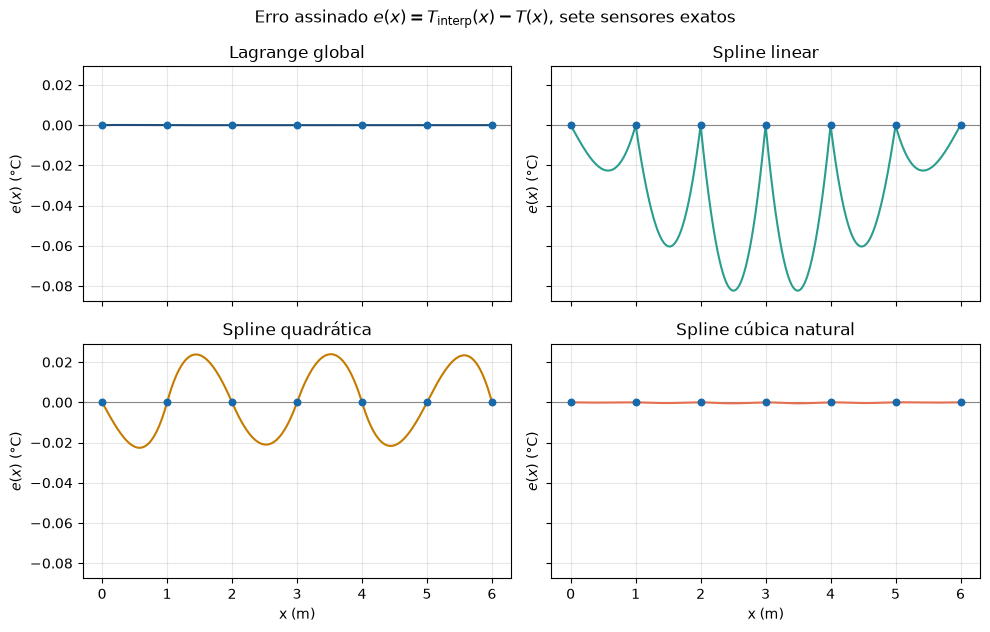

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
for ax, (nome, metodo) in zip(eixos.ravel(), metodos_7.items()):
    erro = np.asarray(metodo(x_fino), dtype=float) - T_fino
    ax.axhline(0, color="#888888", lw=0.8)
    ax.plot(x_fino, erro, color=cores[nome], lw=1.5)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), s=22, color="#1769aa", zorder=4)
    ax.set_title(nome)
    ax.set_ylabel(r"$e(x)$ (°C)")
    ax.grid(True, alpha=0.3)
for ax in eixos[1]:
    ax.set_xlabel("x (m)")
fig.suptitle(r"Erro assinado $e(x)=T_{\mathrm{interp}}(x)-T(x)$, sete sensores exatos")
fig.tight_layout()
plt.show()


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

,N,Nós,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçado,4.530e-03,2.160e-03
1,5,Chebyshev–Lobatto,2.327e-03,1.533e-03
2,9,Equiespaçado,1.044e-06,3.438e-07
3,9,Chebyshev–Lobatto,2.168e-07,1.202e-07
4,13,Equiespaçado,5.916e-11,1.546e-11
5,13,Chebyshev–Lobatto,3.631e-12,1.932e-12
6,17,Equiespaçado,1.990e-12,2.445e-13
7,17,Chebyshev–Lobatto,1.066e-14,3.805e-15


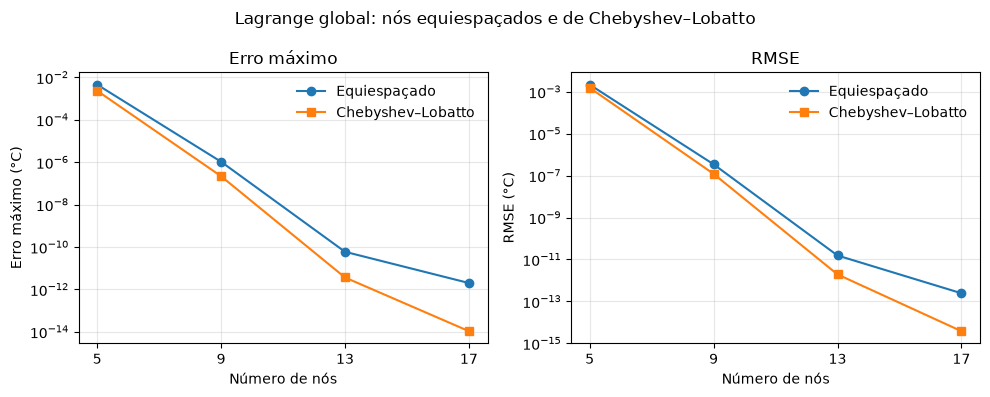

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k * np.pi / (N - 1))
    return np.sort((a + b) / 2 + (b - a) * z / 2)

def metricas_lagrange(x_nos):
    """Erro máximo e RMSE do polinômio de Lagrange na malha fina."""
    polinomio = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
    erro = np.asarray(polinomio(x_fino), dtype=float) - T_fino
    return np.max(np.abs(erro)), np.sqrt(np.mean(erro**2))

linhas_nos = []
for N in (5, 9, 13, 17):
    distribuicoes = {
        "Equiespaçado": np.linspace(x_min, x_max, N),
        "Chebyshev–Lobatto": nos_chebyshev_lobatto(x_min, x_max, N),
    }
    for nome, x_nos in distribuicoes.items():
        emax, rmse = metricas_lagrange(x_nos)
        linhas_nos.append({
            "N": N,
            "Nós": nome,
            "Erro máximo (°C)": emax,
            "RMSE (°C)": rmse,
        })

tabela_nos = pd.DataFrame(linhas_nos)
mostrar_tabela(
    tabela_nos,
    colunas_cientificas=("Erro máximo (°C)", "RMSE (°C)"),
)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for nome, estilo in (("Equiespaçado", "o-"), ("Chebyshev–Lobatto", "s-")):
    parte = tabela_nos[tabela_nos["Nós"] == nome]
    eixos[0].plot(parte["N"], parte["Erro máximo (°C)"], estilo, label=nome)
    eixos[1].plot(parte["N"], parte["RMSE (°C)"], estilo, label=nome)
for ax, titulo in zip(eixos, ("Erro máximo", "RMSE")):
    ax.set_yscale("log")
    ax.set_xlabel("Número de nós")
    ax.set_ylabel(f"{titulo} (°C)")
    ax.set_title(titulo)
    ax.set_xticks((5, 9, 13, 17))
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(frameon=False)
fig.suptitle("Lagrange global: nós equiespaçados e de Chebyshev–Lobatto")
fig.tight_layout()
plt.show()

### Leitura da etapa 2

Nos quatro valores de $N$, o erro cai várias ordens de grandeza nas duas distribuições. Com $N=5$ o erro máximo ainda é de alguns milésimos de grau. Com $N=17$ os dois polinômios já estão no nível do arredondamento: cerca de $2\times 10^{-12}\ ^\circ$C nos nós equiespaçados e $10^{-14}\ ^\circ$C nos nós de Chebyshev–Lobatto.

O perfil de referência é uma reta somada a um seno de meio período. É uma função muito lisa, e um polinômio de grau moderado já a representa bem. Chebyshev reduz o erro em todos os $N$ testados, mas a vantagem só aparece com clareza na escala logarítmica. Essa queda não vale para qualquer função. Um perfil com variação forte perto das pontas, ou com singularidades próximas do intervalo, faz o polinômio equiespaçado oscilar. Aqui a suavidade do seno é que adia esse efeito.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

,N,Método,Erro máximo (°C),RMSE (°C),Construção (ms),Avaliação (ms)
0,4,Lagrange equiespaçado,1.090e-01,6.830e-02,0.055,0.129
1,4,Lagrange Chebyshev,1.430e-01,8.094e-02,0.053,0.129
2,4,Spline cúbica natural,1.018e-02,4.787e-03,0.182,0.030
9,7,Lagrange equiespaçado,8.468e-05,3.271e-05,0.068,0.162
10,7,Lagrange Chebyshev,3.352e-05,1.732e-05,0.069,0.162
11,7,Spline cúbica natural,5.060e-04,2.391e-04,0.179,0.030
33,15,Lagrange equiespaçado,9.379e-13,1.187e-13,0.112,0.238
34,15,Lagrange Chebyshev,2.132e-14,6.537e-15,0.114,0.236
35,15,Spline cúbica natural,1.661e-05,7.553e-06,0.179,0.030
63,25,Lagrange equiespaçado,4.165e-10,3.172e-11,0.169,0.312


Erro máximo (°C)                             RMSE (°C)  \
                                   min        median       max           min   
Método                                                                         
Lagrange Chebyshev        1.065814e-14  1.776357e-14  0.142977  3.861539e-15   
Lagrange equiespaçado     9.379164e-13  9.098294e-09  0.109039  1.187493e-13   
Spline cúbica natural     2.745707e-07  3.279130e-06  0.010177  1.237740e-07   

                                              Construção (ms)                  \
                             median       max             min  median     max   
Método                                                                          
Lagrange Chebyshev     4.536058e-15  0.080945          0.0532  0.1512  0.2485   
Lagrange equiespaçado  1.648762e-09  0.068296          0.0549  0.1511  0.2852   
Spline cúbica natural  1.479438e-06  0.004787          0.1722  0.1790  0.1955   

                      Avaliação (ms)                  
                                 min  median     max  
Método                                                
Lagrange Chebyshev            0.1294  0.2950  0.4551  
Lagrange equiespaçado         0.1287  0.2985  0.6458  
Spline cúbica natural         0.0299  0.0303  0.0560

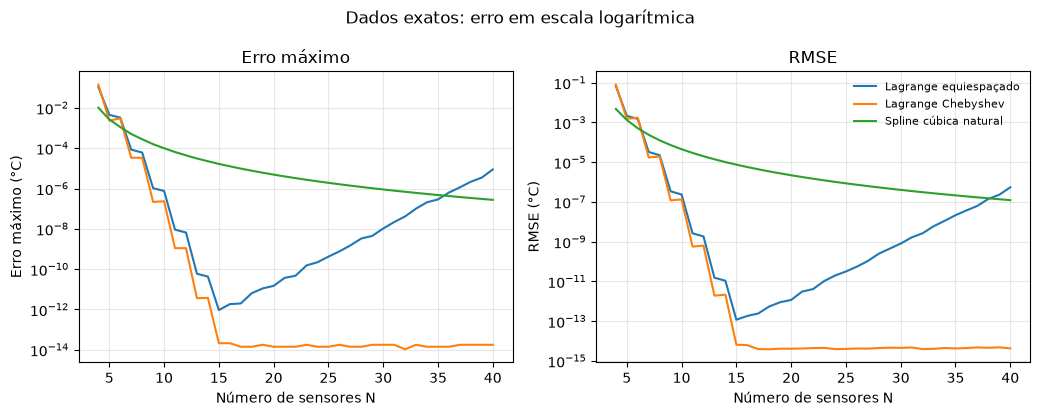

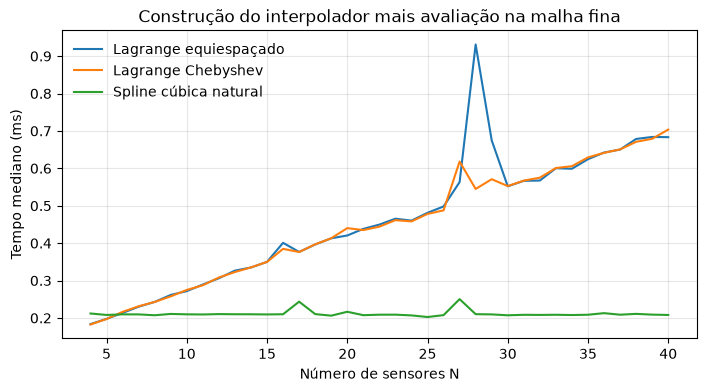

In [ ]:
import time

def cronometrar(funcao, repeticoes=25):
    """Executa a função várias vezes e devolve o último resultado e o tempo mediano."""
    amostras = []
    resultado = None
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        resultado = funcao()
        amostras.append(time.perf_counter() - inicio)
    return resultado, float(np.median(amostras))

registros = []
for N in range(4, 41):
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)
    casos = (
        ("Lagrange equiespaçado", lambda x=x_eq, y=y_eq: BarycentricInterpolator(x, y)),
        ("Lagrange Chebyshev", lambda x=x_ch, y=y_ch: BarycentricInterpolator(x, y)),
        ("Spline cúbica natural", lambda x=x_eq, y=y_eq: CubicSpline(x, y, bc_type="natural")),
    )
    for nome, construir in casos:
        metodo, t_construcao = cronometrar(construir)
        _, t_avaliacao = cronometrar(lambda metodo=metodo: np.asarray(metodo(x_fino)))
        erro = np.asarray(metodo(x_fino), dtype=float) - T_fino
        registros.append({
            "N": N,
            "Método": nome,
            "Erro máximo (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
            "Construção (ms)": 1e3 * t_construcao,
            "Avaliação (ms)": 1e3 * t_avaliacao,
        })

tabela_n = pd.DataFrame(registros)
resumo_n = (
    tabela_n.groupby("Método")[["Erro máximo (°C)", "RMSE (°C)", "Construção (ms)", "Avaliação (ms)"]]
    .agg(["min", "median", "max"])
)
destaques = tabela_n[tabela_n["N"].isin([4, 7, 15, 25, 40])].copy()
mostrar_tabela(
    destaques,
    colunas_cientificas=("Erro máximo (°C)", "RMSE (°C)"),
    colunas_decimais=("Construção (ms)", "Avaliação (ms)"),
)
display(resumo_n)

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.2))
for nome in ("Lagrange equiespaçado", "Lagrange Chebyshev", "Spline cúbica natural"):
    parte = tabela_n[tabela_n["Método"] == nome]
    eixos[0].plot(parte["N"], parte["Erro máximo (°C)"], label=nome)
    eixos[1].plot(parte["N"], parte["RMSE (°C)"], label=nome)
for ax, titulo in zip(eixos, ("Erro máximo", "RMSE")):
    ax.set_yscale("log")
    ax.set_xlabel("Número de sensores N")
    ax.set_ylabel(f"{titulo} (°C)")
    ax.set_title(titulo)
    ax.grid(True, which="both", alpha=0.3)
eixos[1].legend(frameon=False, fontsize=8)
fig.suptitle("Dados exatos: erro em escala logarítmica")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 4))
for nome in ("Lagrange equiespaçado", "Lagrange Chebyshev", "Spline cúbica natural"):
    parte = tabela_n[tabela_n["Método"] == nome]
    ax.plot(parte["N"], parte["Construção (ms)"] + parte["Avaliação (ms)"], label=nome)
ax.set_xlabel("Número de sensores N")
ax.set_ylabel("Tempo mediano (ms)")
ax.set_title("Construção do interpolador mais avaliação na malha fina")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
plt.show()

### Leitura da etapa 3

Não há um método superior para todo $N$. O perfil é liso, mas o comportamento muda com o número de sensores.

- Com $N=4$, a spline cúbica natural é a melhor: erro máximo de cerca de $0{,}010\ ^\circ$C e RMSE de $0{,}0048\ ^\circ$C. Os dois polinômios de Lagrange ficam em torno de $0{,}11\ ^\circ$C e $0{,}14\ ^\circ$C. Um polinômio global de grau 3 ainda não acompanha o arco do seno tão bem quanto pedaços cúbicos.
- A partir de $N=7$, os polinômios passam à frente nos dados exatos. Em $N=7$, o RMSE é $3{,}3\times 10^{-5}\ ^\circ$C no Lagrange equiespaçado, $1{,}7\times 10^{-5}\ ^\circ$C no de Chebyshev e $2{,}4\times 10^{-4}\ ^\circ$C na spline.
- O erro polinomial cai muito depressa enquanto o cálculo permanece estável. Em $N=15$ o Chebyshev já chega a cerca de $10^{-14}\ ^\circ$C, que é o patamar do arredondamento, e permanece nele até $N=40$.
- O Lagrange equiespaçado também cai até cerca de $N=15$ e depois volta a subir. Em $N=40$ o erro máximo é cerca de $9\times 10^{-6}\ ^\circ$C e se concentra junto das extremidades. A função continua lisa; o que cresce é a constante de Lebesgue dos nós igualmente espaçados, que amplifica o arredondamento nas pontas.
- A spline cúbica melhora de forma estável o tempo todo. Em $N=40$ o erro máximo é cerca de $2{,}7\times 10^{-7}\ ^\circ$C. A convergência é mais lenta que a do polinômio no trecho em que o polinômio ainda é estável, e não apresenta oscilação.

O custo, neste tamanho de problema, não decide a escolha. Construir qualquer um dos três métodos leva menos de $0{,}3$ ms até $N=40$. Avaliar os 2001 pontos da malha fina custa cerca de $0{,}03$ ms na spline e cresce com $N$ no Lagrange, chegando a cerca de $1{,}2$ ms em $N=40$. A diferença que importa é a estabilidade, não o tempo.

### Medições com ruído

Os sensores reais não devolvem $T(x_i)$. Acrescentamos um ruído gaussiano independente, de desvio padrão $\sigma=0{,}2\ ^\circ$C, e repetimos o sorteio 30 vezes. A tabela mostra a mediana do erro máximo e do RMSE na malha fina. A curva ilustra uma única realização com sete sensores.

,N,Método,Emax mediano (°C),RMSE mediano (°C)
0,7,Lagrange equiespaçado,4.800e-01,2.451e-01
1,7,Lagrange Chebyshev,3.779e-01,1.934e-01
2,7,Spline cúbica natural,3.335e-01,1.711e-01
3,7,Spline linear,3.228e-01,1.597e-01
4,13,Lagrange equiespaçado,5.831e+00,1.427e+00
5,13,Lagrange Chebyshev,4.138e-01,1.942e-01
6,13,Spline cúbica natural,3.939e-01,1.898e-01
7,13,Spline linear,3.859e-01,1.670e-01
8,25,Lagrange equiespaçado,9.121e+03,1.449e+03
9,25,Lagrange Chebyshev,4.487e-01,1.835e-01


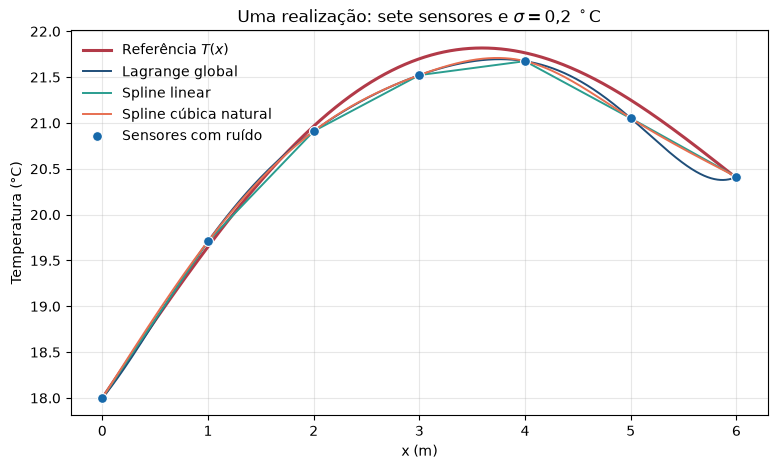

In [ ]:
sigma = 0.2
n_realizacoes = 30
metodos_ruido = (
    "Lagrange equiespaçado",
    "Lagrange Chebyshev",
    "Spline cúbica natural",
    "Spline linear",
)

linhas_ruido = []
for N in (7, 13, 25):
    amostras = {nome: [] for nome in metodos_ruido}
    for semente in range(n_realizacoes):
        gerador = np.random.default_rng(1000 + semente)
        x_eq = np.linspace(x_min, x_max, N)
        y_eq = temperatura_real(x_eq) + gerador.normal(0.0, sigma, size=N)
        x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
        y_ch = temperatura_real(x_ch) + gerador.normal(0.0, sigma, size=N)
        construidos = {
            "Lagrange equiespaçado": BarycentricInterpolator(x_eq, y_eq),
            "Lagrange Chebyshev": BarycentricInterpolator(x_ch, y_ch),
            "Spline cúbica natural": CubicSpline(x_eq, y_eq, bc_type="natural"),
            "Spline linear": interp1d(x_eq, y_eq, kind="linear"),
        }
        for nome, metodo in construidos.items():
            erro = np.asarray(metodo(x_fino), dtype=float) - T_fino
            amostras[nome].append((np.max(np.abs(erro)), np.sqrt(np.mean(erro**2))))
    for nome, valores in amostras.items():
        matriz = np.asarray(valores)
        linhas_ruido.append({
            "N": N,
            "Método": nome,
            "Emax mediano (°C)": np.median(matriz[:, 0]),
            "RMSE mediano (°C)": np.median(matriz[:, 1]),
        })

tabela_ruido = pd.DataFrame(linhas_ruido)
mostrar_tabela(
    tabela_ruido,
    colunas_cientificas=("Emax mediano (°C)", "RMSE mediano (°C)"),
)

gerador = np.random.default_rng(7)
y_ruido_7 = temperatura_real(x_nos_7) + gerador.normal(0.0, sigma, size=len(x_nos_7))
metodos_ruido_7 = criar_metodos(x_nos_7, y_ruido_7)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_fino, T_fino, color="#b23a48", lw=2.2, label=r"Referência $T(x)$")
for nome in ("Lagrange global", "Spline linear", "Spline cúbica natural"):
    ax.plot(x_fino, metodos_ruido_7[nome](x_fino), lw=1.4, color=cores[nome], label=nome)
ax.scatter(x_nos_7, y_ruido_7, s=50, facecolor="#1769aa", edgecolor="white",
           linewidth=0.8, zorder=5, label="Sensores com ruído")
ax.set_xlabel("x (m)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title(r"Uma realização: sete sensores e $\sigma = 0{,}2\ ^\circ$C")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
plt.show()

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Recomendação técnica

A comparação usa o erro máximo e o RMSE na malha fina, em °C.

**Poucos sensores exatos.** Com quatro sensores, a spline cúbica natural é a melhor escolha: o RMSE cai para cerca de $0{,}005\ ^\circ$C, enquanto o Lagrange fica em torno de $0{,}07\ ^\circ$C. Com sete sensores exatos o Lagrange fica ainda menor (RMSE de $3\times 10^{-5}\ ^\circ$C, contra $2\times 10^{-4}\ ^\circ$C da spline), mas os dois erros já são irrelevantes diante de um termômetro de verdade. Eu adotaria a spline cúbica nesse regime: ela acompanha o arco da temperatura com poucos pontos e não depende de um polinômio global.

**Ao aumentar o número de sensores.** Não existe um método superior para todo $N$. Com dados exatos, o Lagrange de Chebyshev chega ao arredondamento por volta de $N=15$ e permanece estável. O Lagrange equiespaçado melhora até esse ponto e depois piora nas extremidades, por causa da constante de Lebesgue. A spline cúbica continua melhorando, de forma mais lenta e sem oscilação. Se as posições puderem ser escolhidas e as leituras forem muito precisas, Chebyshev é o mais preciso. Se as posições forem fixas e igualmente espaçadas, eu paro de usar o polinômio global quando $N$ passa de cerca de 15 e fico com a spline.

**Sensores com ruído.** Com $\sigma=0{,}2\ ^\circ$C, o RMSE mediano dos métodos estáveis fica entre $0{,}16\ ^\circ$C e $0{,}25\ ^\circ$C. Aumentar $N$ não recupera a temperatura verdadeira abaixo do ruído do instrumento. O Lagrange equiespaçado amplifica esse ruído: o RMSE mediano passa de cerca de $1{,}4\ ^\circ$C com 13 sensores para milhares de graus com 25. Eu usaria a spline linear ou a cúbica. A linear teve o menor RMSE mediano, porque não oscila entre medidas ruidosas. Chebyshev também permanece estável, desde que a posição dos sensores possa ser essa. A interpolação passa por todas as leituras, inclusive as erradas. Se o objetivo for o perfil liso da barra, e não a medida pontual, uma curva suavizada é mais adequada do que forçar a passagem por todos os pontos.

**Extremidades.** O erro do polinômio equiespaçado, e também a amplificação do ruído, concentram-se perto de $x=0$ e de $x=L$. As temperaturas das pontas são condições de contorno conhecidas, $18{,}0\ ^\circ$C e $20{,}4\ ^\circ$C, e devem entrar como nós exatos, sem o ruído dos sensores internos. Sem um sensor na ponta, eu não confiaria no último intervalo.

**Interpolação e extrapolação.** Dentro do trecho coberto pelos sensores, a curva interpola. Fora dele, o polinômio de grau alto se afasta depressa, e a spline apenas prolonga o polinômio da extremidade. A barra existe em $[0,L]$. Estimar temperatura além do primeiro ou do último sensor não tem apoio nas medições.

**Quando a temperatura verdadeira é desconhecida.** O erro máximo, o MAE e o RMSE contra $T(x)$ deixam de poder ser calculados. O resíduo nos próprios sensores é praticamente zero por construção da interpolação e não mede o erro entre os nós. O que resta é comparar os métodos entre si, repetir o ajuste deixando um sensor de fora e tratar a incerteza do instrumento como um limite inferior do erro da estimativa.